# Bike Buyers: Analysis & Purchase Prediction

**Business question:** which customer profiles buy a bike, and can we predict a purchase from demographics?

| Track | What this notebook does |
|---|---|
| **Data analytics** | load, audit, clean, engineer features, explore (purchase rate by segment) |
| **Data science** | leakage-free preprocessing pipeline, baseline vs. models, cross-validation, tuning, evaluation, feature importance, saved model |

**Dataset:** `Excel Project Dataset - pandas.xlsx` (1,000 customers, 12 attributes + target `Purchased Bike`).

## 1. Setup

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, classification_report,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from xgboost import XGBClassifier

SEED = 42  # reproducibility
sns.set_theme(style="whitegrid")

IMG_DIR, MODEL_DIR, REPORT_DIR = Path("images"), Path("models"), Path("reports")
for folder in (IMG_DIR, MODEL_DIR, REPORT_DIR):
    folder.mkdir(exist_ok=True)

## 2. Load & audit the data

In [2]:
DATA_FILE = "Excel Project Dataset - pandas.xlsx"
data_path = next((p for p in (Path(DATA_FILE), Path("data") / DATA_FILE) if p.exists()), None)
if data_path is None:
    raise FileNotFoundError(f"'{DATA_FILE}' not found: place it next to this notebook (or in ./data/).")

raw = pd.read_excel(data_path)
print(f"Loaded {raw.shape[0]} rows x {raw.shape[1]} columns from '{data_path}'")
raw.head(3)

Loaded 1000 rows x 13 columns from 'Excel Project Dataset - pandas.xlsx'


,ID,Marital Status,Gender,Income,Children,Education,Occupation,Home Owner,Cars,Commute Distance,Region,Age,Purchased Bike
0,12496,M,F,40000,1,Bachelors,Skilled Manual,Yes,0,0-1 Miles,Europe,42,No
1,24107,M,M,30000,3,Partial College,Clerical,Yes,1,0-1 Miles,Europe,43,No
2,14177,M,M,80000,5,Partial College,Professional,No,2,2-5 Miles,Europe,60,No


In [3]:
raw.info()
print("\nMissing values per column:")
print(raw.isna().sum().to_string())
print("\nDuplicated customer IDs:", raw["ID"].duplicated().sum())
raw.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   ID                1000 non-null   int64 
 1   Marital Status    1000 non-null   object
 2   Gender            1000 non-null   object
 3   Income            1000 non-null   int64 
 4   Children          1000 non-null   int64 
 5   Education         1000 non-null   object
 6   Occupation        1000 non-null   object
 7   Home Owner        1000 non-null   object
 8   Cars              1000 non-null   int64 
 9   Commute Distance  1000 non-null   object
 10  Region            1000 non-null   object
 11  Age               1000 non-null   int64 
 12  Purchased Bike    1000 non-null   object
dtypes: int64(5), object(8)
memory usage: 101.7+ KB

Missing values per column:
ID                  0
Marital Status      0
Gender              0
Income              0
Children            0
Education     

,ID,Income,Children,Cars,Age
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,19965.992000,56360.000000,1.898000,1.442000,44.163000
std,5347.333948,31085.635215,1.628572,1.125123,11.364488
min,11000.000000,10000.000000,0.000000,0.000000,25.000000
25%,15290.750000,30000.000000,0.000000,1.000000,35.000000
50%,19744.000000,60000.000000,2.000000,1.000000,43.000000
75%,24470.750000,70000.000000,3.000000,2.000000,52.000000
max,29447.000000,170000.000000,5.000000,4.000000,89.000000


## 3. Data cleaning

- Duplicates are detected on **`ID`** (two different customers can legitimately share all attributes), then the identifier is dropped.
- Codes are replaced by readable labels (`M/S`, `M/F`).
- A validation step fails loudly if an unexpected category appears (instead of silently creating `NaN` like a bare `.map()` would).
- Missing values are **not** filled here: imputation happens inside the model pipeline, fitted on training data only.

In [4]:
df = raw.copy()
df.columns = df.columns.str.strip()

# 1) duplicates on the customer identifier, then drop the identifier (no predictive meaning)
df = df.drop_duplicates(subset="ID").drop(columns="ID")

# 2) trim whitespace in text columns
text_cols = df.select_dtypes(exclude="number").columns
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())

# 3) readable labels
df["Marital Status"] = df["Marital Status"].replace({"M": "Married", "S": "Single"})
df["Gender"] = df["Gender"].replace({"M": "Male", "F": "Female"})

# 4) validate categories (ordered lists are reused later for plots and encoding)
EDU_ORDER = ["Partial High School", "High School", "Partial College", "Bachelors", "Graduate Degree"]
COMMUTE_ORDER = ["0-1 Miles", "1-2 Miles", "2-5 Miles", "5-10 Miles", "10+ Miles"]
EXPECTED = {
    "Marital Status": {"Married", "Single"},
    "Gender": {"Male", "Female"},
    "Home Owner": {"Yes", "No"},
    "Purchased Bike": {"Yes", "No"},
    "Education": set(EDU_ORDER),
    "Commute Distance": set(COMMUTE_ORDER),
    "Occupation": {"Professional", "Skilled Manual", "Clerical", "Management", "Manual"},
    "Region": {"North America", "Europe", "Pacific"},
}
for col, allowed in EXPECTED.items():
    unexpected = set(df[col].dropna().unique()) - allowed
    assert not unexpected, f"'{col}': unexpected values {unexpected}"

print(f"Clean dataset: {df.shape[0]} rows x {df.shape[1]} columns")
df["Commute Distance"].value_counts().reindex(COMMUTE_ORDER)

Clean dataset: 1000 rows x 12 columns


Commute Distance
0-1 Miles     366
1-2 Miles     169
2-5 Miles     162
5-10 Miles    192
10+ Miles     111
Name: count, dtype: int64

## 4. Feature engineering

`Age Group` is used for **analysis only** (the model keeps the raw `Age`). The labels fix the original ones: 30 is not an "adolescent", and the categories are now ordered.

In [5]:
df["Age Group"] = pd.cut(
    df["Age"], bins=[0, 30, 54, 120],
    labels=["Young (<=30)", "Middle-aged (31-54)", "Senior (55+)"],
)

# Income outliers (IQR rule): reported, kept (tree-based models are robust to them)
q1, q3 = df["Income"].quantile([0.25, 0.75])
iqr = q3 - q1
is_outlier = (df["Income"] < q1 - 1.5 * iqr) | (df["Income"] > q3 + 1.5 * iqr)
print(f"Income outliers: {is_outlier.sum()} rows ({is_outlier.mean():.1%})")
df["Age Group"].value_counts().sort_index()

Income outliers: 10 rows (1.0%)


Age Group
Young (<=30)           110
Middle-aged (31-54)    701
Senior (55+)           189
Name: count, dtype: int64

## 5. Exploratory data analysis

In [10]:
print("Target balance (% of customers):")
print(df["Purchased Bike"].value_counts(normalize=True).mul(100).round(1).to_string())

Target balance (% of customers):
Purchased Bike
No     51.9
Yes    48.1


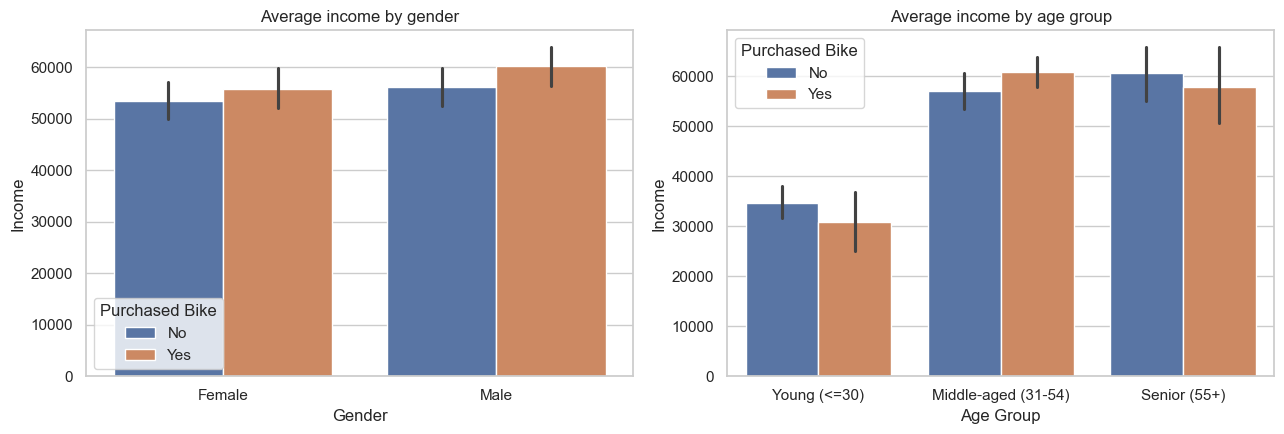

In [11]:
# Average income by segment and purchase decision
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=df, x="Gender", y="Income", hue="Purchased Bike", ax=axes[0])
axes[0].set_title("Average income by gender")
sns.barplot(data=df, x="Age Group", y="Income", hue="Purchased Bike", ax=axes[1])
axes[1].set_title("Average income by age group")
fig.tight_layout()
fig.savefig(IMG_DIR / "income_by_segment.png", dpi=150, bbox_inches="tight")
plt.show()

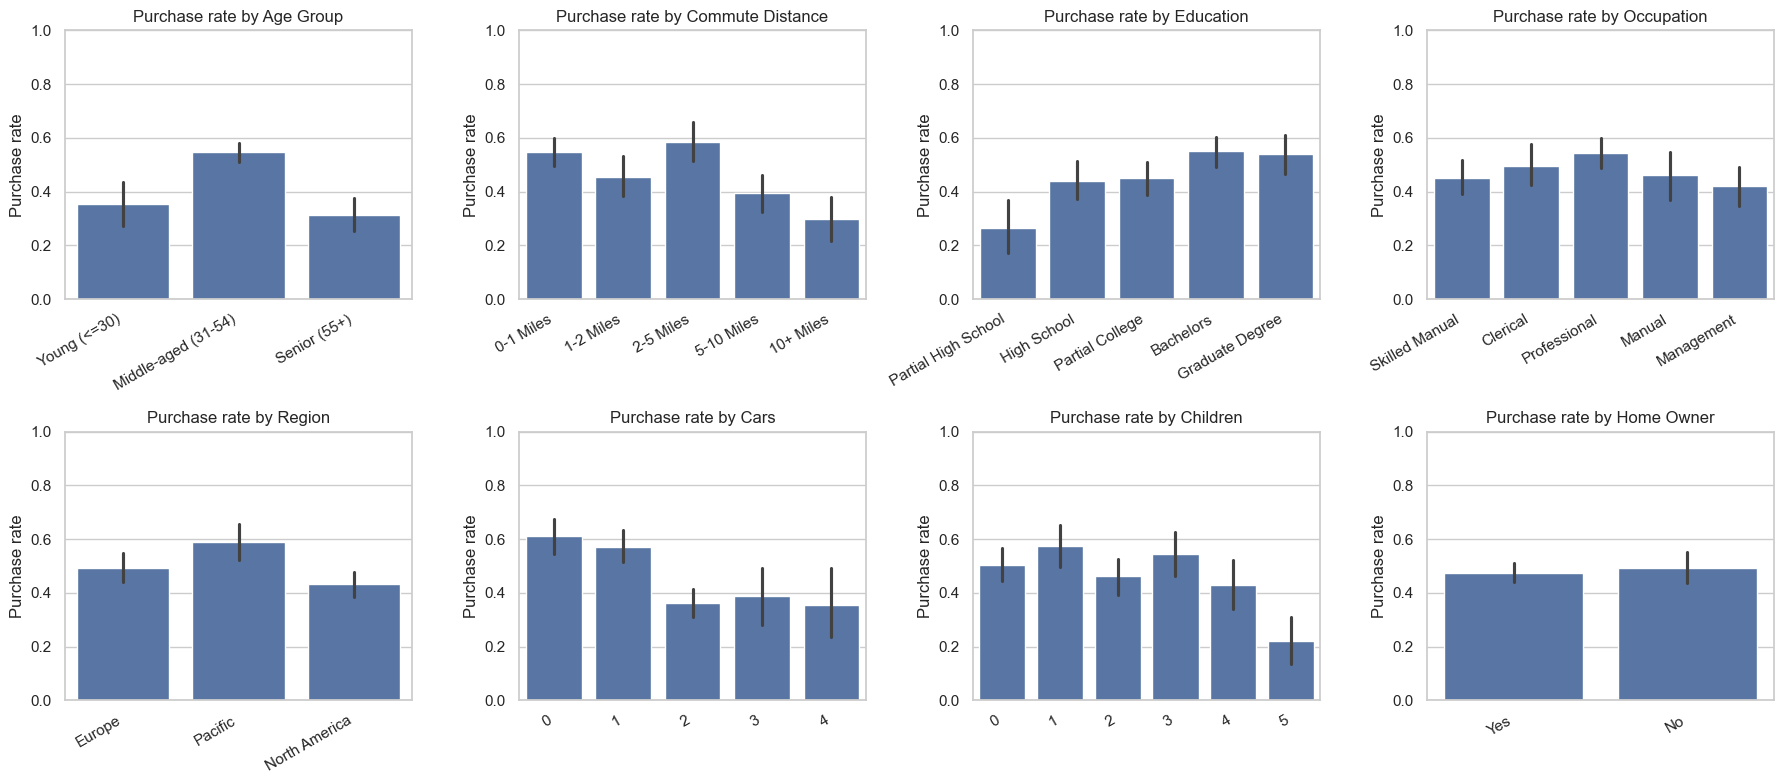

In [12]:
# Purchase rate by segment (a proportion, so bars are far more meaningful than the line plots of v1)
plot_df = df.assign(**{"Purchase rate": (df["Purchased Bike"] == "Yes").astype(int)})
segments = [
    ("Age Group", None), ("Commute Distance", COMMUTE_ORDER), ("Education", EDU_ORDER), ("Occupation", None),
    ("Region", None), ("Cars", None), ("Children", None), ("Home Owner", None),
]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (col, order) in zip(axes.ravel(), segments):
    sns.barplot(data=plot_df, x=col, y="Purchase rate", order=order, color="#4C72B0", ax=ax)
    ax.set_ylim(0, 1)
    ax.set_title(f"Purchase rate by {col}")
    ax.set_xlabel("")
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig(IMG_DIR / "purchase_rate_by_segment.png", dpi=150, bbox_inches="tight")
plt.show()

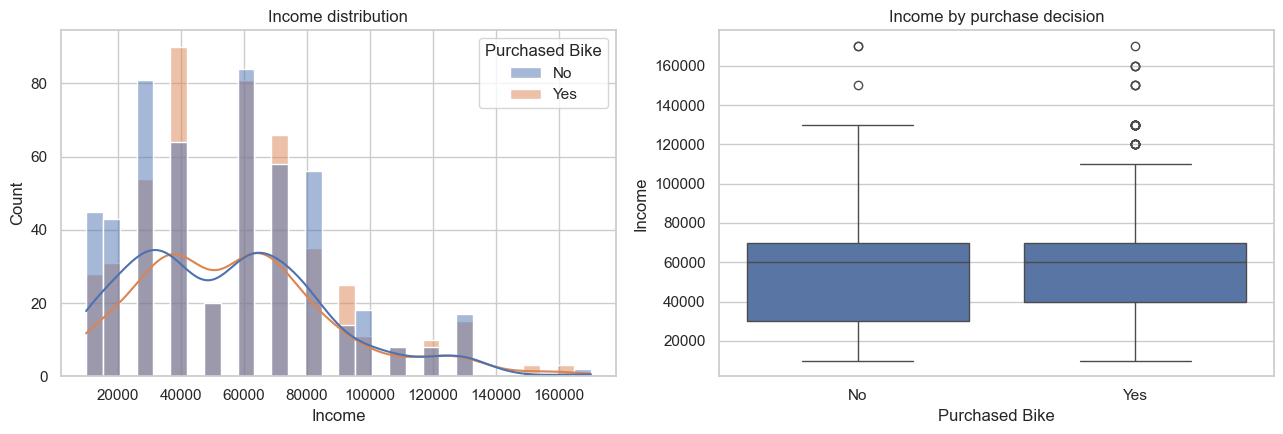

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="Income", hue="Purchased Bike", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Income distribution")
sns.boxplot(data=df, x="Purchased Bike", y="Income", ax=axes[1])
axes[1].set_title("Income by purchase decision")
fig.tight_layout()
fig.savefig(IMG_DIR / "income_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Modelling

**Fixes compared with v1**

| Issue in v1 | Fix |
|---|---|
| `MinMaxScaler` fitted on the **whole** dataset before the split (data leakage), and useless for tree models | scaling only where needed (logistic regression), fitted inside a `Pipeline` on training folds |
| Nominal variables (`Occupation`, `Region`) and `Education` encoded with arbitrary integers | one-hot for nominal, **logical order** for `Education` / `Commute Distance` |
| No `random_state`, no stratification | `SEED = 42`, `stratify=y` |
| Accuracy only, on one 200-row test set | baseline, 5-fold CV, ROC-AUC / F1 / precision / recall, confusion matrix |
| Hyper-parameters never tuned (and XGBoost tested directly on the test set) | `RandomizedSearchCV` on the training set, test set used **once** |

In [14]:
y = (df["Purchased Bike"] == "Yes").astype(int)
X = df.drop(columns=["Purchased Bike", "Age Group"])  # Age Group is derived from Age

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train {X_train.shape} | Test {X_test.shape} | purchase rate: train {y_train.mean():.1%}, test {y_test.mean():.1%}")

Train (800, 11) | Test (200, 11) | purchase rate: train 48.1%, test 48.0%


In [15]:
NUMERIC = ["Income", "Age", "Children", "Cars"]
BINARY = ["Marital Status", "Gender", "Home Owner"]
ORDINAL = {"Education": EDU_ORDER, "Commute Distance": COMMUTE_ORDER}
NOMINAL = ["Occupation", "Region"]


def make_preprocessor(scale: bool) -> ColumnTransformer:
    """Imputation + encoding, fitted on training data only (inside the pipeline)."""
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUMERIC),
        ("bin", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))]), BINARY),
        ("ord", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OrdinalEncoder(categories=list(ORDINAL.values())))]), list(ORDINAL)),
        ("nom", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore"))]), NOMINAL),
    ])


models = {
    "Baseline (majority class)": Pipeline([("prep", make_preprocessor(False)),
                                           ("model", DummyClassifier(strategy="most_frequent"))]),
    "Logistic Regression": Pipeline([("prep", make_preprocessor(True)),
                                     ("model", LogisticRegression(max_iter=1000, random_state=SEED))]),
    "Random Forest": Pipeline([("prep", make_preprocessor(False)),
                               ("model", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]),
    "XGBoost": Pipeline([("prep", make_preprocessor(False)),
                         ("model", XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                                                 eval_metric="logloss", random_state=SEED, n_jobs=-1))]),
}

### 6.1 Cross-validated comparison (training set only)

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}

rows = []
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"Model": name, **{m: res[f"test_{m}"].mean() for m in scoring},
                 "roc_auc_std": res["test_roc_auc"].std()})
cv_results = pd.DataFrame(rows).set_index("Model").round(3).sort_values("roc_auc", ascending=False)
cv_results

,accuracy,f1,roc_auc,roc_auc_std
Model,,,,
Random Forest,0.720,0.705,0.800,0.034
XGBoost,0.708,0.702,0.754,0.036
Logistic Regression,0.642,0.606,0.675,0.028
Baseline (majority class),0.519,0.000,0.500,0.000


### 6.2 Hyper-parameter tuning

In [17]:
param_spaces = {
    "Random Forest": {
        "model__n_estimators": [200, 300, 500], "model__max_depth": [None, 5, 8, 12],
        "model__min_samples_leaf": [1, 2, 5, 10], "model__max_features": ["sqrt", 0.5, None],
    },
    "XGBoost": {
        "model__n_estimators": [100, 200, 300, 500], "model__max_depth": [2, 3, 4, 6],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1], "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.7, 0.85, 1.0], "model__min_child_weight": [1, 3, 5],
    },
}

tuned = {}
for name, space in param_spaces.items():
    search = RandomizedSearchCV(models[name], space, n_iter=20, scoring="roc_auc", cv=cv,
                                random_state=SEED, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search
    print(f"{name}: best CV ROC-AUC = {search.best_score_:.3f}")
    print(f"  {search.best_params_}")

Random Forest: best CV ROC-AUC = 0.792
  {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': None}
XGBoost: best CV ROC-AUC = 0.763
  {'model__subsample': 0.7, 'model__n_estimators': 200, 'model__min_child_weight': 1, 'model__max_depth': 6, 'model__learning_rate': 0.01, 'model__colsample_bytree': 1.0}


### 6.3 Final evaluation on the held-out test set

The best model is chosen on **cross-validation score**, not on the test set.

In [18]:
final_models = {
    "Baseline (majority class)": models["Baseline (majority class)"].fit(X_train, y_train),
    "Logistic Regression": models["Logistic Regression"].fit(X_train, y_train),
    "Random Forest (tuned)": tuned["Random Forest"].best_estimator_,
    "XGBoost (tuned)": tuned["XGBoost"].best_estimator_,
}


def evaluate(pipe):
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }


test_results = pd.DataFrame({name: evaluate(m) for name, m in final_models.items()}).T.round(3)

best_name = max(tuned, key=lambda k: tuned[k].best_score_)  # selected on CV
best_model = tuned[best_name].best_estimator_
print(f"Selected model (best CV ROC-AUC): {best_name}")
test_results

Selected model (best CV ROC-AUC): Random Forest


,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline (majority class),0.520,0.000,0.000,0.000,0.500
Logistic Regression,0.620,0.616,0.552,0.582,0.690
Random Forest (tuned),0.675,0.682,0.604,0.641,0.746
XGBoost (tuned),0.705,0.703,0.667,0.684,0.752


              precision    recall  f1-score   support

          No       0.67      0.76      0.71       104
         Yes       0.70      0.59      0.64        96

    accuracy                           0.68       200
   macro avg       0.68      0.68      0.68       200
weighted avg       0.68      0.68      0.68       200



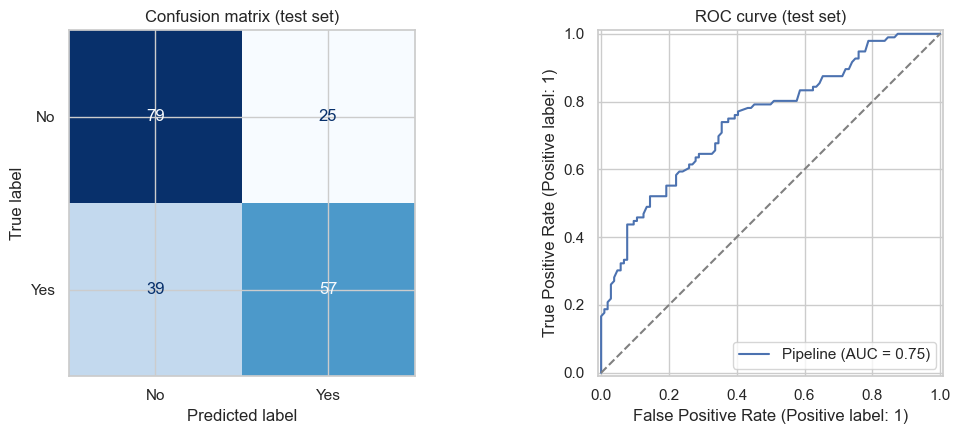

In [19]:
print(classification_report(y_test, best_model.predict(X_test), target_names=["No", "Yes"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, display_labels=["No", "Yes"],
                                      cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix (test set)")
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_title("ROC curve (test set)")
fig.tight_layout()
fig.savefig(IMG_DIR / "model_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.4 Which features matter? (permutation importance)

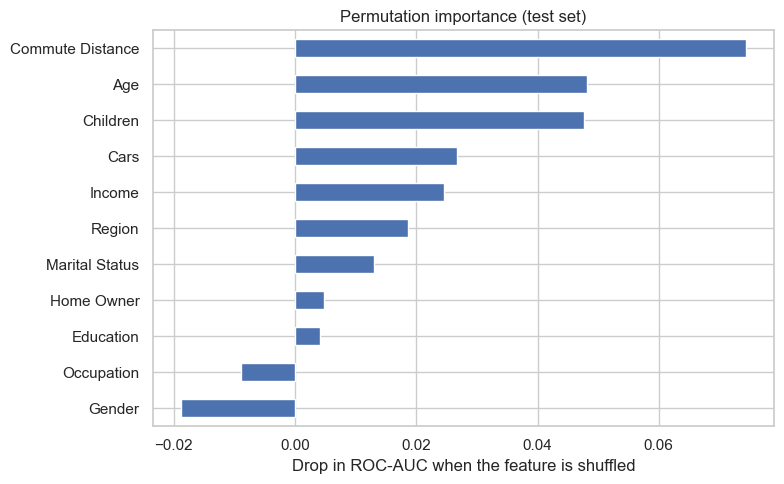

In [20]:
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=SEED, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

ax = importance.plot.barh(figsize=(8, 5), color="#4C72B0")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
ax.set_title("Permutation importance (test set)")
plt.tight_layout()
plt.savefig(IMG_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Save artefacts & predict for a new customer

In [ ]:
joblib.dump(best_model, MODEL_DIR / "best_model.joblib")
cv_results.to_csv(REPORT_DIR / "cv_metrics.csv")
test_results.to_csv(REPORT_DIR / "test_metrics.csv")

new_customer = pd.DataFrame([{
    "Marital Status": "Married", "Gender": "Female", "Income": 60000, "Children": 2,
    "Education": "Bachelors", "Occupation": "Professional", "Home Owner": "Yes", "Cars": 1,
    "Commute Distance": "0-1 Miles", "Region": "Europe", "Age": 35,
}])
loaded = joblib.load(MODEL_DIR / "best_model.joblib")
print(f"Probability of buying a bike: {loaded.predict_proba(new_customer)[0, 1]:.1%}")

## 8. Conclusions & limitations

- Read the metrics above against the **baseline**: a model is only useful if it clearly beats the majority-class predictor.
- With ~200 test rows, the standard error of accuracy is about 3 points: differences smaller than that between models are noise, which is why cross-validation is used for selection.
- The dataset has demographics only (no price, channel or behaviour data), so predictive power is naturally limited.
- **Next steps:** probability calibration, SHAP explanations, a Streamlit app serving `models/best_model.joblib`.